# Condition classifier: which of 6 oral conditions are in a phone photo (multi-label)

**Data:** the Roboflow *oral-diseases* v2 export, prepared by `models/classifier/scripts/Aiden/prepare_roboflow_multilabel.py`.
**Task:** a photo can show several conditions at once (e.g. calculus *and* gingivitis), so the model answers
**yes/no for each condition separately** instead of picking one class. There is no Normal (healthy) class:
"no condition above its threshold" is the closest the model gets to "looks healthy", and it was never trained on healthy mouths.
**Model:** DenseNet-121 pretrained on ImageNet, fine-tuned in two stages, one sigmoid output per condition.
**Main metrics:** per-condition recall and F1, and macro average precision (AP, threshold-free). A missed condition
(false negative) is the costly error.

Runs locally from the repo (data in `data/processed/classifier_multilabel`, outputs to `models/classifier/results/Aiden`),
or on Kaggle with **GPU T4** and **Internet on**: upload `classifier_multilabel` (without `_cache`) as a private dataset.

## 1. Setup

In [1]:
import os, random
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn
from PIL import Image
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import models, transforms
from sklearn.metrics import (average_precision_score, classification_report, f1_score,
                             multilabel_confusion_matrix, ConfusionMatrixDisplay)

SEED, IMG, BATCH = 42, 224, 32
FROZEN_EPOCHS, FINETUNE_EPOCHS, PATIENCE = 5, 25, 5
PER_PHOTO = False    # each original photo equally likely per epoch (section 4); False = every training image once per epoch
EPOCH_PASSES = 3     # with PER_PHOTO: an epoch draws 3 x (number of training photos) images

SMOKE = os.environ.get("SMOKE") == "1"   # tiny CPU test run only; leave unset for real runs
ON_KAGGLE = Path("/kaggle/input").exists()
if SMOKE:
    DATA_DIR, OUT_DIR = Path(os.environ["DATA_DIR"]), Path(os.environ["OUT_DIR"])
    FROZEN_EPOCHS, FINETUNE_EPOCHS = 1, 1
elif ON_KAGGLE:
    DATA_DIR = next(Path("/kaggle/input").rglob("manifest.csv")).parent
    OUT_DIR = Path("/kaggle/working")
else:
    REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / ".git").exists())
    DATA_DIR = REPO / "data/processed/classifier_multilabel"
    OUT_DIR = REPO / "models/classifier/results/Aiden"
    OUT_DIR.mkdir(parents=True, exist_ok=True)
assert (DATA_DIR / "manifest.csv").exists(), f"no manifest.csv in {DATA_DIR}: run prepare_roboflow_multilabel.py first"
PRETRAINED = not SMOKE

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEV = "cuda" if torch.cuda.is_available() else "cpu"
print("data:", DATA_DIR, "| device:", DEV)

data: C:\Users\aiden\Downloads\AI WIU\Deep-Learning-WIU\data\processed\classifier_multilabel | device: cuda


## 2. Look at the data

15061 images from 1791 original photos
       images  photos
split                
test      119     119
train   14786    1516
val       156     156

images with each condition, per split:
split                train  val  test
Calculus              3168   58    36
Caries                5591   76    49
Gingivitis            2672   52    43
Hypodontia            3120   24    29
Tooth_Discoloration   6522   79    63
Mouth_Ulcer           3862   43    28


C:\Users\aiden\AppData\Local\Temp\ipykernel_10332\2744313027.py:16: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  photos[CLASSES].sum(1).value_counts().sort_index().plot.bar(ax=ax[1], title="Conditions per photo", xlabel="number of conditions")


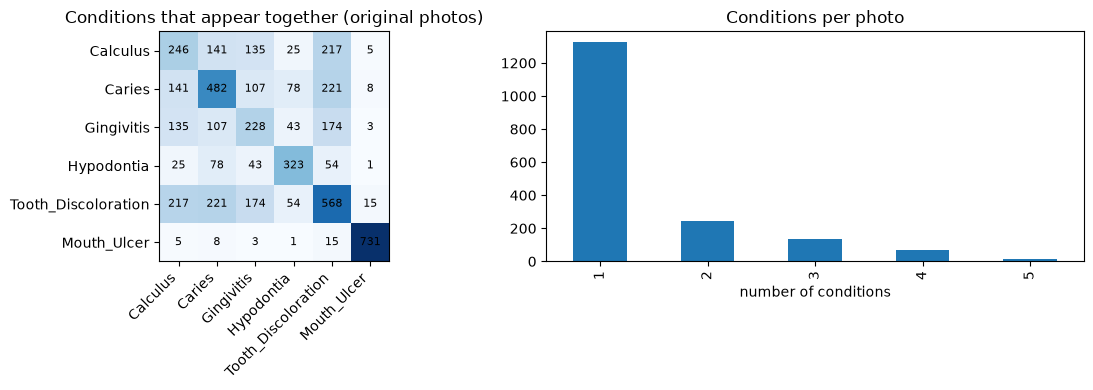

In [2]:
df = pd.read_csv(DATA_DIR / "manifest.csv")
CLASSES = [c for c in df.columns if c not in ("file", "split", "group", "split_group")]
photos = df.drop_duplicates("group")   # one row per original photo
print(f"{len(df)} images from {len(photos)} original photos")
print(df.groupby("split").agg(images=("file", "size"), photos=("group", "nunique")))
print("\nimages with each condition, per split:")
print(df.groupby("split")[CLASSES].sum().T[["train", "val", "test"]])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
co = photos[CLASSES].T.dot(photos[CLASSES])   # diagonal = photos with the condition, off-diagonal = photos with both
ax[0].imshow(co, cmap="Blues"); ax[0].set_xticks(range(len(CLASSES)), CLASSES, rotation=45, ha="right"); ax[0].set_yticks(range(len(CLASSES)), CLASSES)
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        ax[0].text(j, i, co.iloc[i, j], ha="center", va="center", fontsize=8)
ax[0].set_title("Conditions that appear together (original photos)")
photos[CLASSES].sum(1).value_counts().sort_index().plot.bar(ax=ax[1], title="Conditions per photo", xlabel="number of conditions")
plt.tight_layout(); plt.show()

## 3. How the split avoids leakage

The raw export holds many cropped / rotated / recoloured copies of each original photo, and Roboflow's own split puts copies
of the same photo in train *and* test: a model could then score well by remembering photos instead of recognising conditions.
`prepare_roboflow_multilabel.py` finds the copies (DINOv2 proposes similar images, SIFT keypoint matching confirms them) and
gives all copies of one original photo the same `group` (>= 40 matching keypoints). Weaker copies (>= 10) link photos into a
`split_group`, and split groups are split 70/15/15, so not even a weak copy crosses between train, val and test.
Val/test keep **one image per split group**, so no two val/test images are copies of each other either.

Check the examples below: every row should be one photo shown several times. If a row mixes different mouths, the matching
threshold (`GROUP_INLIERS` in the script) is too loose.

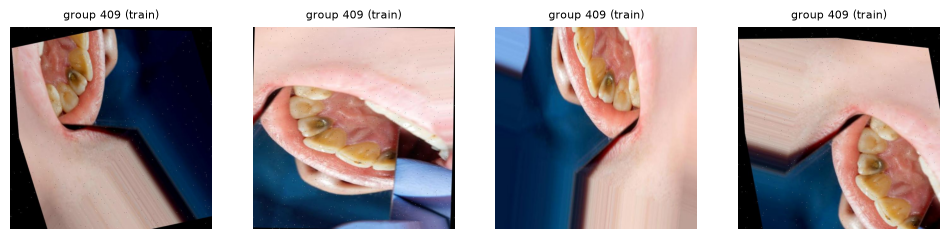

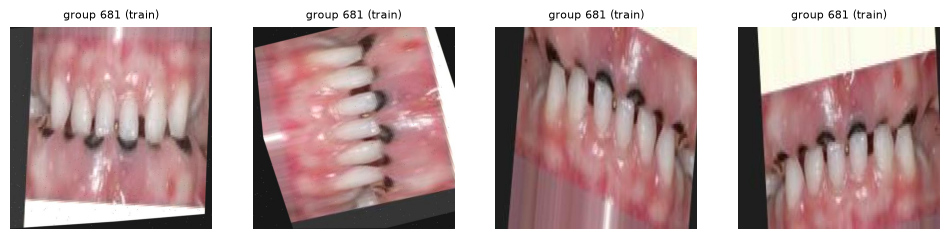

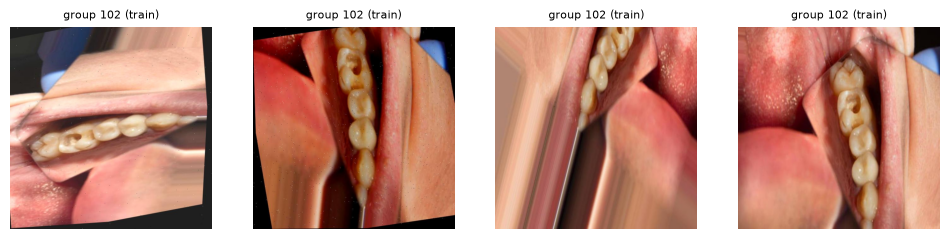

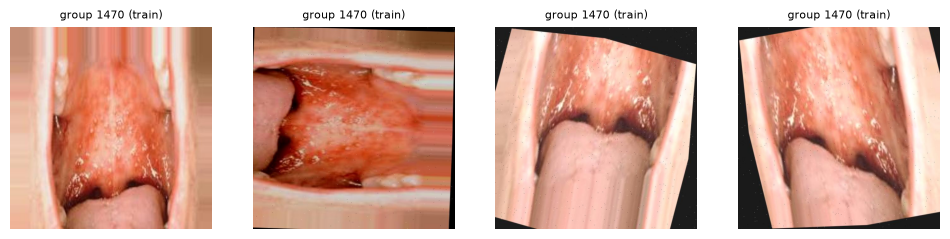

In [3]:
assert not set(df[df.split == "train"].split_group) & set(df[df.split != "train"].split_group), "leak: copy in train and val/test"
assert df[df.split != "train"].split_group.is_unique, "val/test should hold one image per split group"
df.to_csv(OUT_DIR / "splits.csv", index=False)

big = df.group.value_counts()
for g in big[big >= 4].sample(min(4, (big >= 4).sum()), random_state=SEED).index:
    rows = df[df.group == g].sample(4, random_state=SEED)
    fig, axes = plt.subplots(1, 4, figsize=(12, 3))
    for ax, r in zip(axes, rows.itertuples()):
        ax.imshow(Image.open(DATA_DIR / r.file)); ax.axis("off"); ax.set_title(f"group {g} ({r.split})", fontsize=8)
    plt.show()

## 4. Data loading and augmentation

Augmentation only changes position and light a little. **No hue or saturation changes:** tooth discolouration *is* a colour,
so changing colour would teach the model to ignore it. Each image's target is a 0/1 vector, one entry per condition.

**Per-photo sampling (`PER_PHOTO`).** Training keeps every copy of a photo (copies inside train are not leakage: they act like
extra augmentation), but some photos have 1 copy and some have over 100. Shown once each per epoch, those few photos would
outvote the rest and the model would memorise them. So each image is drawn with probability 1 / (copies of its photo):
every original photo is equally likely, and a different copy of it comes up each time.

In [4]:
NORM = transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
eval_tf = transforms.Compose([transforms.Resize((IMG, IMG)), transforms.ToTensor(), NORM])
train_tf = transforms.Compose([
    transforms.Resize((IMG + 16, IMG + 16)), transforms.RandomCrop(IMG),
    transforms.RandomHorizontalFlip(), transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(), NORM])

class OralDS(Dataset):
    def __init__(self, frame, tf):
        self.files = frame.file.tolist()
        self.y = torch.tensor(frame[CLASSES].values, dtype=torch.float32)
        self.tf = tf
    def __len__(self):
        return len(self.files)
    def __getitem__(self, i):
        return self.tf(Image.open(DATA_DIR / self.files[i]).convert("RGB")), self.y[i]

part = {s: df[df.split == s] for s in ("train", "val", "test")}
workers = 2 if ON_KAGGLE else 0   # Windows Jupyter cannot start loader workers for a class defined in the notebook
train_ds = OralDS(part["train"], train_tf)
if PER_PHOTO:
    copies = part["train"].group.map(part["train"].group.value_counts()).values
    n_photos = part["train"].group.nunique()
    sampler = WeightedRandomSampler(torch.tensor(1.0 / copies, dtype=torch.double), EPOCH_PASSES * n_photos, replacement=True)
    train_dl = DataLoader(train_ds, BATCH, sampler=sampler, num_workers=workers)
    print(f"per-photo sampling: {n_photos} photos ({len(train_ds)} images), {EPOCH_PASSES * n_photos} draws per epoch")
else:
    train_dl = DataLoader(train_ds, BATCH, shuffle=True, num_workers=workers)
val_dl = DataLoader(OralDS(part["val"], eval_tf), BATCH, num_workers=workers)
test_dl = DataLoader(OralDS(part["test"], eval_tf), BATCH, num_workers=workers)

## 5. Model and loss

One output per condition, each squashed to a probability by a sigmoid (independent yes/no answers, unlike softmax which
forces the classes to compete). The loss is binary cross-entropy per condition. `pos_weight` = negatives / positives in
the training set, so a rare condition's missed positives cost as much in total as its true negatives. With `PER_PHOTO`
it is counted over original photos, because that is how often the model sees each condition.

In [5]:
weights = models.DenseNet121_Weights.IMAGENET1K_V1 if PRETRAINED else None

def new_model():
    m = models.densenet121(weights=weights)
    m.classifier = nn.Linear(m.classifier.in_features, len(CLASSES))
    return m.to(DEV)

counted = part["train"].drop_duplicates("group") if PER_PHOTO else part["train"]   # copies share their photo's labels
pos = counted[CLASSES].sum().values
pos_weight = torch.tensor((len(counted) - pos) / np.maximum(pos, 1), dtype=torch.float32, device=DEV)
crit = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
print(dict(zip(CLASSES, pos_weight.cpu().numpy().round(2))))

{'Calculus': np.float32(3.67), 'Caries': np.float32(1.64), 'Gingivitis': np.float32(4.53), 'Hypodontia': np.float32(3.74), 'Tooth_Discoloration': np.float32(1.27), 'Mouth_Ulcer': np.float32(2.83)}


## 6. Training: frozen backbone first, then fine-tune

The best epoch is chosen by **validation macro AP** (average precision per condition, averaged). AP does not depend on a
decision threshold, which is only chosen afterwards (section 7). The test set is not touched until section 8.

In [6]:
def macro_ap(y, p):
    return np.mean([average_precision_score(y[:, c], p[:, c]) for c in range(len(CLASSES)) if y[:, c].any()])

def run_epoch(model, loader, opt=None):
    training = opt is not None
    model.train(training)
    total, ys, probs = 0.0, [], []
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(DEV), y.to(DEV)
            out = model(x)
            loss = crit(out, y)
            if training:
                opt.zero_grad(); loss.backward(); opt.step()
            total += loss.item() * len(y)
            ys.append(y.cpu()); probs.append(torch.sigmoid(out).detach().cpu())
    ys, probs = torch.cat(ys).numpy(), torch.cat(probs).numpy()
    return total / len(ys), macro_ap(ys, probs), ys, probs

history, best = [], {"ap": -1.0}

def fit(model, epochs, lr, stage):
    opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=lr, weight_decay=1e-4)
    stale = 0
    for ep in range(1, epochs + 1):
        tl, tap, _, _ = run_epoch(model, train_dl, opt)
        vl, vap, _, _ = run_epoch(model, val_dl)
        history.append(dict(stage=stage, epoch=ep, train_loss=tl, train_ap=tap, val_loss=vl, val_ap=vap))
        line = f"{stage} {ep:2d}  train loss {tl:.3f} AP {tap:.3f} | val loss {vl:.3f} AP {vap:.3f}"
        print(line)
        with open(OUT_DIR / "train_log.txt", "a") as log:   # readable while a long run is still going
            print(line, file=log)
        if vap > best["ap"]:
            best["ap"] = vap
            torch.save(model.state_dict(), OUT_DIR / "best.pt")
            stale = 0
        else:
            stale += 1
            if stale >= PATIENCE:
                print("early stop: validation AP stopped improving"); break

model = new_model()
for p in model.features.parameters():
    p.requires_grad = False
fit(model, FROZEN_EPOCHS, 1e-3, "frozen")
for p in model.parameters():
    p.requires_grad = True
fit(model, FINETUNE_EPOCHS, 1e-4, "finetune")

frozen  1  train loss 0.629 AP 0.772 | val loss 0.768 AP 0.769


frozen  2  train loss 0.500 AP 0.839 | val loss 0.791 AP 0.765


frozen  3  train loss 0.469 AP 0.857 | val loss 0.806 AP 0.774


frozen  4  train loss 0.452 AP 0.864 | val loss 0.848 AP 0.772


frozen  5  train loss 0.442 AP 0.868 | val loss 0.932 AP 0.769


finetune  1  train loss 0.218 AP 0.962 | val loss 1.159 AP 0.851


... (7 outputs left out)

finetune  9  train loss 0.024 AP 0.999 | val loss 1.683 AP 0.856


finetune 10  train loss 0.014 AP 1.000 | val loss 1.535 AP 0.865


finetune 11  train loss 0.013 AP 1.000 | val loss 2.127 AP 0.851


finetune 12  train loss 0.016 AP 1.000 | val loss 1.680 AP 0.862
early stop: validation AP stopped improving


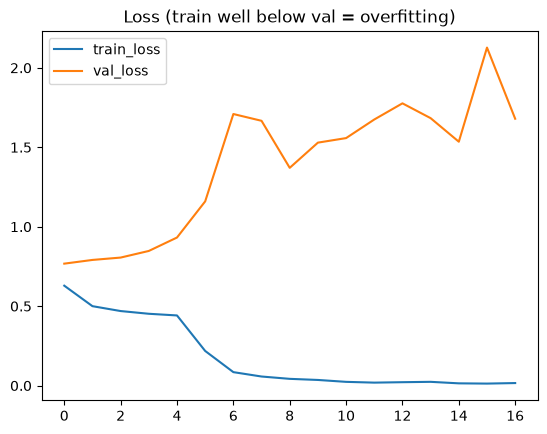

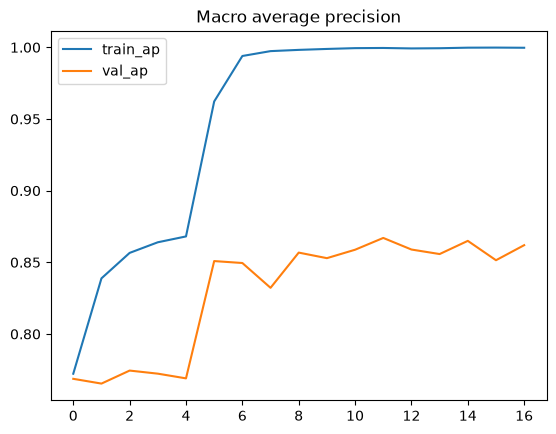

In [7]:
h = pd.DataFrame(history)
h.to_csv(OUT_DIR / "history.csv", index=False)
h[["train_loss", "val_loss"]].plot(title="Loss (train well below val = overfitting)")
h[["train_ap", "val_ap"]].plot(title="Macro average precision"); plt.show()

## 7. Decision threshold per condition (chosen on validation)

A probability becomes a yes/no answer with a threshold. 0.5 is arbitrary, and rare conditions usually need a lower one.
Each condition's threshold is the one with the best F1 **on the validation set**; choosing it on the test set would be leakage.

In [8]:
model.load_state_dict(torch.load(OUT_DIR / "best.pt", map_location=DEV))
_, val_ap, val_y, val_p = run_epoch(model, val_dl)
grid = np.linspace(0.05, 0.95, 19)
THRESH = np.array([grid[np.argmax([f1_score(val_y[:, c], val_p[:, c] >= t, zero_division=0) for t in grid])]
                   for c in range(len(CLASSES))])
print(f"val macro AP {val_ap:.3f}")
print(pd.DataFrame({"threshold": THRESH, "val F1 at threshold":
                    [f1_score(val_y[:, c], val_p[:, c] >= THRESH[c], zero_division=0) for c in range(len(CLASSES))]},
                   index=CLASSES).round(3))

val macro AP 0.867
                     threshold  val F1 at threshold
Calculus                  0.15                0.793
Caries                    0.10                0.821
Gingivitis                0.10                0.723
Hypodontia                0.50                0.744
Tooth_Discoloration       0.10                0.867
Mouth_Ulcer               0.95                0.941


## 8. Final test (run once, at the end)

                     precision    recall  f1-score   support

           Calculus      0.622     0.778     0.691        36
             Caries      0.662     0.878     0.754        49
         Gingivitis      0.935     0.674     0.784        43
         Hypodontia      0.900     0.621     0.735        29
Tooth_Discoloration      0.810     0.810     0.810        63
        Mouth_Ulcer      0.964     0.964     0.964        28

          micro avg      0.778     0.790     0.784       248
          macro avg      0.816     0.787     0.790       248
       weighted avg      0.803     0.790     0.786       248
        samples avg      0.838     0.832     0.797       248

average precision (threshold-free):
            Calculus  0.735
              Caries  0.822
          Gingivitis  0.890
          Hypodontia  0.836
 Tooth_Discoloration  0.900
         Mouth_Ulcer  0.970
            macro AP  0.859
exact match (all 6 answers right): 0.403


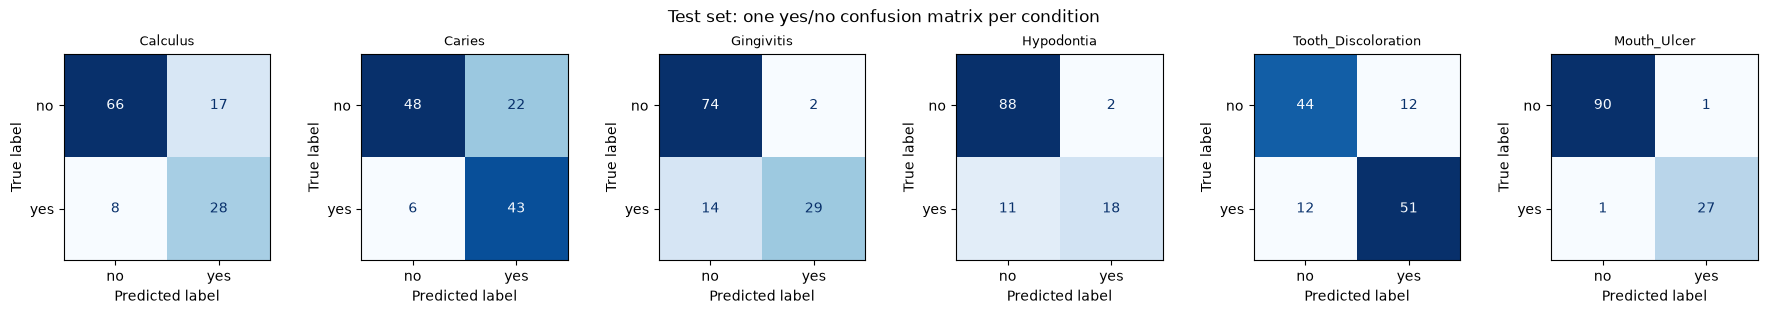

In [9]:
_, test_ap, test_y, test_p = run_epoch(model, test_dl)
pred = test_p >= THRESH
ap = [average_precision_score(test_y[:, c], test_p[:, c]) if test_y[:, c].any() else float("nan") for c in range(len(CLASSES))]
report = classification_report(test_y, pred, target_names=CLASSES, digits=3, zero_division=0)
report += "\naverage precision (threshold-free):\n" + "\n".join(f"{c:>20s}  {a:.3f}" for c, a in zip(CLASSES, ap))
report += f"\n{'macro AP':>20s}  {test_ap:.3f}\nexact match (all {len(CLASSES)} answers right): {(pred == test_y).all(1).mean():.3f}"
print(report)
(OUT_DIR / "test_report.txt").write_text(report)

fig, axes = plt.subplots(1, len(CLASSES), figsize=(3 * len(CLASSES), 3))
for ax, c, m in zip(axes, CLASSES, multilabel_confusion_matrix(test_y, pred)):
    ConfusionMatrixDisplay(m, display_labels=["no", "yes"]).plot(ax=ax, colorbar=False, cmap="Blues"); ax.set_title(c, fontsize=9)
plt.suptitle("Test set: one yes/no confusion matrix per condition"); plt.tight_layout(); plt.show()

## 9. Grad-CAM: where is the model looking for each condition?

For each condition, a test photo that has it, and the heat map for **that condition's** output. Red areas pushed that
probability up most. Heat on lips, background, black borders or smeared edges instead of teeth/gums means a shortcut.

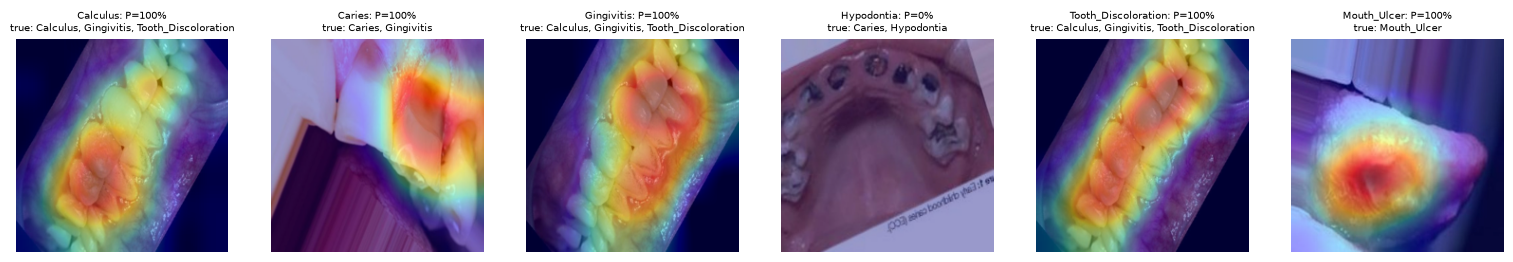

In [10]:
def grad_cam(model, x, cls):
    # DenseNet's forward() is written out here so we can take the gradient at its last feature maps
    # (a hook would break: DenseNet applies an in-place ReLU right after them)
    model.eval()
    act = torch.relu(model.features(x))
    out = model.classifier(act.mean((2, 3)))
    grad, = torch.autograd.grad(out[0, cls], act)
    w = grad.mean((2, 3), keepdim=True)
    cam = torch.relu((w * act).sum(1))[0]
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    return cam.detach().cpu().numpy(), torch.sigmoid(out[0, cls]).item()

fig, axes = plt.subplots(1, len(CLASSES), figsize=(3.2 * len(CLASSES), 3.6))
for ax, (c, name) in zip(axes, enumerate(CLASSES)):
    has = part["test"][part["test"][name] == 1]
    if has.empty:
        ax.axis("off"); continue
    r = has.iloc[0]
    img = Image.open(DATA_DIR / r.file).convert("RGB").resize((IMG, IMG))
    cam, p = grad_cam(model, eval_tf(img).unsqueeze(0).to(DEV), c)
    ax.imshow(img); ax.imshow(Image.fromarray(np.uint8(cam * 255)).resize((IMG, IMG)), cmap="jet", alpha=0.4)
    true = ", ".join(k for k in CLASSES if r[k])
    ax.set_title(f"{name}: P={p:.0%}\ntrue: {true}", fontsize=7); ax.axis("off")
plt.show()

## 10. Save the model for the app

In [11]:
torch.save({"state_dict": model.state_dict(), "classes": CLASSES, "thresholds": THRESH.tolist(), "multilabel": True,
            "img_size": IMG, "arch": "densenet121"}, OUT_DIR / "condition_classifier.pt")
print("saved", OUT_DIR / "condition_classifier.pt")

saved C:\Users\aiden\Downloads\AI WIU\Deep-Learning-WIU\models\classifier\results\Aiden\condition_classifier.pt


## Experiment log (fill in one row per run; this is the evidence for "systematic and iterative" optimisation)

| Run | What changed | Why | Val macro AP | Caries recall | Notes |
|---|---|---|---|---|---|
| 1 | Baseline: DenseNet-121, multi-label (sigmoid + BCE with pos_weight, per-condition thresholds); copy-aware 70/15/15 split by original photo; `PER_PHOTO = False` | starting point | 0.839 (fine-tune epoch 7; stopped at 12) | 0.853 (test, n=102) | Local RTX 4060, ~3 min/epoch. Test macro AP 0.829, macro-F1 0.766, exact match 0.549. Per-condition test AP: Calculus 0.719 (n=71), Caries 0.782 (102), Gingivitis 0.819 (70), Hypodontia 0.769 (37), Tooth_Discoloration 0.894 (138), Mouth_Ulcer 0.991 (128). Strong overfitting: train AP 1.000 vs val ~0.83, val loss 0.70 -> 1.72. Overconfident: 3 thresholds at the grid minimum 0.05. Grad-CAM: Calculus/Gingivitis/Discoloration heat on teeth; Caries example missed (heat on a smeared edge), Hypodontia example missed (photo has caption text) |
| 2 | Stricter val/test: one image per split group (val 156 / test 119, was 324 / 324); model and training as run 1 | val/test held weaker copies of each other (91 pairs within test at 10-39 keypoints) | 0.867 (fine-tune epoch 7; stopped at 12) | 0.878 (test, n=49) | Test set changed, so not directly comparable with run 1. Test macro AP 0.859 (run 1: 0.829), macro-F1 0.790, exact match 0.403. Per-condition test AP: Calculus 0.735 (n=36), Caries 0.822 (49), Gingivitis 0.890 (43), Hypodontia 0.836 (29), Tooth_Discoloration 0.900 (63), Mouth_Ulcer 0.970 (28). Removing within-test copies did not lower the scores, so they were not inflating run 1. Same overfitting (train AP 1.000, val loss 1.16 -> 2.13). Grad-CAM as run 1: heat on teeth for Calculus/Gingivitis/Discoloration; Hypodontia example still missed (photo with caption text) |
| 3 | (planned) val/test without strong copies of each other only (e.g. >= 20 keypoints), a middle ground between runs 1 and 2 | run 2's test set is small (28-63 positives per condition), so its scores are noisy | | | |
| 4 | `PER_PHOTO = True`: each original photo equally likely per epoch, 3 x photos draws per epoch; pos_weight counted over photos | 65 photos with >= 30 copies made up 26% of training images; Calculus has 114 photos but ~22 copies each | | | |